# 04 — Age-subgroup analysis (exploratory)
The final evaluation (notebook 03) suggested that the guideline rule *"refer if age ≥ 35 and BMI ≥ 25"* misses every young patient,
and that the models catch some of them. That check used only **16 young test cases**, so this notebook asks whether the pattern holds up.

**Ground rules**
- This analysis was added **after** the main evaluation and is **not** one of the pre-set success criteria. It is exploratory.
- Nothing here changes the models, features or thresholds. The saved models and thresholds from notebook 02 are used as they are.
- To get more cases, we also use **out-of-fold predictions on the 614 training patients**. Each training patient is scored by a model that
  never saw them, using the same configuration as the saved models.
- Every rate comes with a **bootstrap 95 % confidence interval**, resampled within each age group.

In [1]:
import sys, json
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.data import load_clean, train_test, TARGET, PROJECT_ROOT
from src.models import GuidelineRule, logistic

sns.set_theme(style="whitegrid")
train, test = train_test(load_clean())
meta = json.loads((PROJECT_ROOT / "models" / "metadata.json").read_text())
models = {k: joblib.load(PROJECT_ROOT / v["file"]) for k, v in meta["models"].items()}
AGE_BINS, AGE_LABELS = [20, 29, 44, 100], ["21–29", "30–44", "45+"]
RNG = np.random.default_rng(42)

## 1. Referral decisions for every patient
- **Test set:** the saved models with their saved standard (matched-rate) thresholds.
- **Training set:** out-of-fold probabilities from a 5-fold split, with the same configuration and the same thresholds.

In [2]:
def decisions(df, probs):
    out = pd.DataFrame({
        "age group": pd.cut(df["Age"], AGE_BINS, labels=AGE_LABELS),
        "diabetes": df[TARGET].to_numpy(),
        "rule": GuidelineRule().predict(df),
    }, index=df.index)
    for key in ["no_lab", "full"]:
        out[key] = (probs[key] >= meta["models"][key]["thresholds"]["matched_rate"]).astype(int)
    return out

test_probs = {k: models[k].predict_proba(test[meta["models"][k]["features"]])[:, 1] for k in models}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
oof_probs = {k: cross_val_predict(logistic(meta["models"][k]["features"]), train[meta["models"][k]["features"]],
                                  train[TARGET], cv=cv, method="predict_proba")[:, 1] for k in models}

dec = pd.concat([decisions(train, oof_probs).assign(data="training (out-of-fold)"),
                 decisions(test, test_probs).assign(data="test")])
dec.groupby(["data", "age group"], observed=True)["diabetes"].agg(patients="size", cases="sum").T

data       test           training (out-of-fold)           
age group 21–29 30–44 45+                  21–29 30–44  45+
patients     85    40  29                    311   199  104
cases        16    26  12                     68    92   54

## 2. Sensitivity by age group (share of diabetes cases referred)

In [3]:
def rate_ci(values, n_boot=4000):
    values = np.asarray(values)
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    boots = [values[RNG.integers(0, len(values), len(values))].mean() for _ in range(n_boot)]
    return values.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

DECIDERS = {"rule": "Guideline rule", "no_lab": "No-lab model", "full": "Full model"}

def by_group(subset_mask_col, value):
    rows = []
    for (data, group), g in dec.groupby(["data", "age group"], observed=True):
        g = g[g[subset_mask_col] == value]
        for col, name in DECIDERS.items():
            est, lo, hi = rate_ci(g[col])
            rows.append({"data": data, "age group": group, "decider": name, "n": len(g),
                         "rate": est, "CI low": lo, "CI high": hi})
    return pd.DataFrame(rows)

sens = by_group("diabetes", 1)
(sens.assign(result=lambda d: d.apply(lambda r: f"{r.rate:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})", axis=1))
     .pivot_table(index=["data", "age group", "n"], columns="decider", values="result", aggfunc="first", observed=True))

decider                                    Full model    Guideline rule  \
data                   age group n                                        
test                   21–29     16  0.38 (0.12–0.62)  0.00 (0.00–0.00)   
                       30–44     26  0.58 (0.38–0.77)  0.62 (0.42–0.81)   
                       45+       12  0.75 (0.50–1.00)  1.00 (1.00–1.00)   
training (out-of-fold) 21–29     68  0.57 (0.46–0.69)  0.00 (0.00–0.00)   
                       30–44     92  0.64 (0.54–0.74)  0.65 (0.55–0.75)   
                       45+       54  0.76 (0.63–0.87)  0.91 (0.81–0.98)   

decider                                  No-lab model  
data                   age group n                     
test                   21–29     16  0.25 (0.06–0.50)  
                       30–44     26  0.50 (0.31–0.69)  
                       45+       12  0.92 (0.75–1.00)  
training (out-of-fold) 21–29     68  0.32 (0.22–0.44)  
                       30–44     92  0.52 (0.41–0.62)  
                       45+       54  0.70 (0.57–0.83)

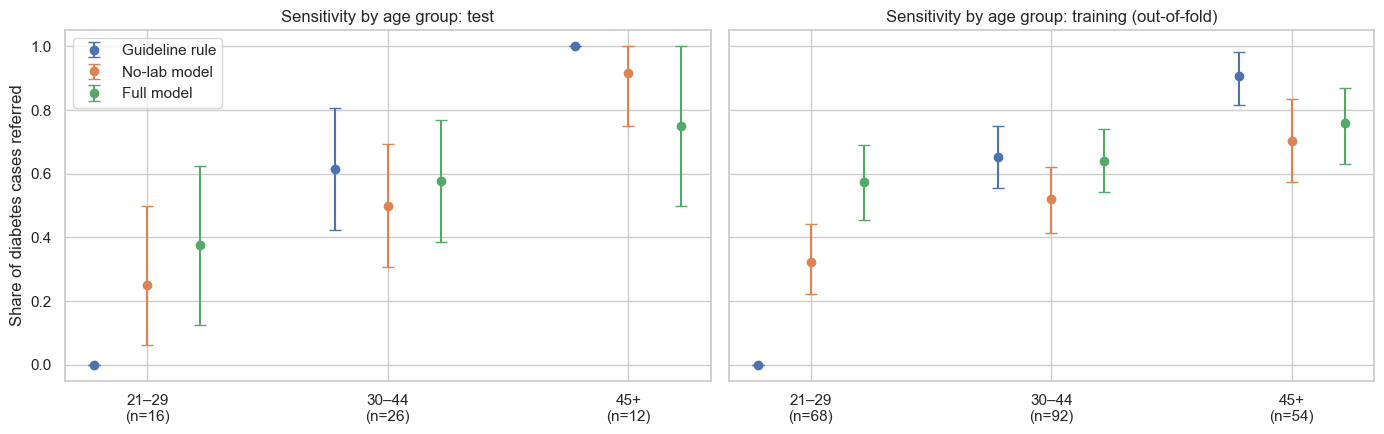

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (data, d) in zip(axes, sens.groupby("data")):
    x = np.arange(len(AGE_LABELS))
    for i, name in enumerate(DECIDERS.values()):
        dd = d[d.decider == name].set_index("age group").reindex(AGE_LABELS)
        ax.errorbar(x + (i - 1) * 0.22, dd["rate"], yerr=[dd["rate"] - dd["CI low"], dd["CI high"] - dd["rate"]],
                    fmt="o", capsize=4, label=name)
    ax.set_xticks(x, [f"{g}\n(n={n})" for g, n in zip(AGE_LABELS, d[d.decider == "Guideline rule"].set_index("age group").reindex(AGE_LABELS)["n"])])
    ax.set_title(f"Sensitivity by age group: {data}")
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("Share of diabetes cases referred")
axes[0].legend()
plt.tight_layout()
plt.show()

**What this shows**
- The training (out-of-fold) results have **4 times as many cases** and show the **same pattern** as the test set. The young-patient finding
  is not a fluke of the 16 test cases.
- **21–29:** the rule catches **none** of the cases (by design: it needs age ≥ 35). The full model catches **57 %** (training) and 38 % (test);
  the no-lab model catches **32 %** and 25 %.
- **45+:** the rule catches the most (91 % training, 100 % test), because almost every older patient meets its age condition.
- **30–44:** the full model and the rule are similar (about 60 %). The no-lab model catches somewhat fewer (about 50 %).

## 3. The other side: who gets referred without diabetes?
Catching more young cases is only half the picture. We also need to know how many patients *without* diabetes each method sends for testing
(the false-positive rate).

In [5]:
fpr = by_group("diabetes", 0)
(fpr.assign(result=lambda d: d.apply(lambda r: f"{r.rate:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})", axis=1))
    .pivot_table(index=["data", "age group", "n"], columns="decider", values="result", aggfunc="first", observed=True))

decider                                     Full model    Guideline rule  \
data                   age group n                                         
test                   21–29     69   0.16 (0.07–0.25)  0.00 (0.00–0.00)   
                       30–44     14   0.36 (0.14–0.64)  0.57 (0.29–0.86)   
                       45+       17   0.35 (0.12–0.59)  0.71 (0.47–0.88)   
training (out-of-fold) 21–29     243  0.07 (0.04–0.11)  0.00 (0.00–0.00)   
                       30–44     107  0.22 (0.15–0.31)  0.50 (0.41–0.60)   
                       45+       50   0.44 (0.30–0.58)  0.78 (0.66–0.88)   

decider                                   No-lab model  
data                   age group n                      
test                   21–29     69   0.13 (0.06–0.22)  
                       30–44     14   0.21 (0.00–0.43)  
                       45+       17   0.71 (0.47–0.88)  
training (out-of-fold) 21–29     243  0.09 (0.05–0.12)  
                       30–44     107  0.38 (0.29–0.48)  
                       45+       50   0.64 (0.52–0.76)

**What this shows**
- For **older patients without diabetes**, the rule refers **50 % (30–44) and 78 % (45+)** of them in training. The models refer far fewer:
  the full model refers 22 % and 44 %.
- For **young patients without diabetes**, the models refer a small share (7–9 % in training) where the rule refers none.
- So the models aren't simply referring *more* people. They **move** referrals away from older patients without diabetes and toward younger
  patients with diabetes. Overall, by design, each method refers about the same share of patients.

## 4. Pooled view: young vs older, all 768 patients
Pooling training (out-of-fold) and test decisions gives the largest sample. We compare patients **under 35**, whom the rule can never refer,
with patients **35 and over**.

In [6]:
dec["under 35"] = np.where(pd.concat([train["Age"], test["Age"]]).loc[dec.index].to_numpy() < 35, "under 35", "35+")
rows = []
for grp, g in dec[dec.diabetes == 1].groupby("under 35"):
    for col, name in DECIDERS.items():
        est, lo, hi = rate_ci(g[col])
        rows.append({"age": grp, "cases": len(g), "decider": name, "sensitivity": f"{est:.2f} ({lo:.2f}–{hi:.2f})"})
pooled = pd.DataFrame(rows).pivot(index=["age", "cases"], columns="decider", values="sensitivity")
pooled

,decider,Full model,Guideline rule,No-lab model
age,cases,,,
35+,142,0.73 (0.65–0.80),0.96 (0.93–0.99),0.65 (0.58–0.73)
under 35,126,0.52 (0.44–0.61),0.00 (0.00–0.00),0.34 (0.26–0.43)


In [7]:
young_cases = dec[(dec.diabetes == 1) & (dec["under 35"] == "under 35")]
for col, name in [("no_lab", "No-lab model"), ("full", "Full model")]:
    diff = young_cases[col].to_numpy() - young_cases["rule"].to_numpy()
    est, lo, hi = rate_ci(diff)
    print(f"{name} − rule, sensitivity for under-35 cases: {est:+.2f} (95% CI {lo:+.2f} to {hi:+.2f}), n={len(diff)} cases")

No-lab model − rule, sensitivity for under-35 cases: +0.34 (95% CI +0.26 to +0.42), n=126 cases
Full model − rule, sensitivity for under-35 cases: +0.52 (95% CI +0.44 to +0.61), n=126 cases


**What this shows**
- **Nearly half of all diabetes cases in this dataset (126 of 268) are in women under 35.** The guideline rule can never refer any of them.
- The no-lab model catches **34 %** of these young cases (95 % CI 26–43 %), and the full model **52 %** (44–61 %).
- In exchange, the models catch fewer cases among women 35+ (no-lab 65 %, full 73 %, vs the rule's 96 %).
- *Caveat:* the rule's 0 % for under-35 is true **by construction**, so the "model − rule" difference is just the models' own catch rate.
  The real finding is the **size of the group the rule can't see**, not that the models are clever.
- *Caveat:* this pools the test set (saved models) with out-of-fold training predictions (re-fitted with the same configuration), so it describes
  the **method** rather than one exact model. And this population has a very high, early-onset diabetes rate, which is why so many cases are young.
  In other populations the share of young cases may be much smaller.

## 5. Conclusions
1. The young-patient gap seen in notebook 03 **holds up** in a sample four times larger. It isn't a small-sample accident.
2. **The rule and the models catch similar numbers of cases but different people.** The rule concentrates on older women, while the models spread
   referrals across ages and refer fewer older women who don't have diabetes.
3. **This changes how the main result should be read.** The no-lab model "did not beat the rule" on *how many* cases it caught. On *which*
   cases it caught, it reaches a group (under-35s, nearly half of all cases here) that the rule cannot reach at all.
4. **This doesn't make the model "better" overall.** It makes a trade-off visible: the rule is better for older patients, and the models are
   better for younger ones. Which trade-off is acceptable is a clinical and policy decision, not a statistical one.
5. **A natural next experiment**, not done here: a hybrid policy, e.g. *refer if the rule says yes, OR if the model's risk is high for a patient
   under 35*. It would need its own pre-set criteria and fresh data to evaluate fairly.